# YOLO26l Training and Evaluation

## Section 1: Install

In [1]:
!pip install -q -U ultralytics

## Section 2: Imports

In [2]:
import os
import asyncio
import json
import time
import shutil
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import userdata, files, drive
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## Section 3: API Key and Google Drive

In [3]:
os.environ['ULTRALYTICS_API_KEY'] = userdata.get('ULTRALYTICS_API_KEY')
assert os.environ.get('ULTRALYTICS_API_KEY'), 'Add ULTRALYTICS_API_KEY to Colab Secrets first.'

drive.mount('/content/drive')
SAVE_ROOT = Path('/content/drive/MyDrive/WildLens_TRAINING')
RESULTS = SAVE_ROOT / 'results_yolo26l'
for d in [SAVE_ROOT / 'runs', RESULTS]:
    d.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


## Section 4: Dataset

In [4]:
uploaded = files.upload()
ndjson_files = [name for name in uploaded if name.lower().endswith('.ndjson')]
assert len(ndjson_files) == 1, f'Upload exactly one .ndjson file; found {len(ndjson_files)}.'
NDJSON_PATH = os.path.abspath(ndjson_files[0])

from ultralytics.data.converter import convert_ndjson_to_yolo

def _convert_ndjson_in_worker():
    return asyncio.run(convert_ndjson_to_yolo(NDJSON_PATH, output_path='/content/converted_datasets'))

with ThreadPoolExecutor(max_workers=1) as executor:
    DATA = str(executor.submit(_convert_ndjson_in_worker).result())
print(DATA)

Saving isy5002-g14-dataset.ndjson to isy5002-g14-dataset.ndjson
Converting isy5002-g14-dataset.ndjson fraction=1.0 → /content/converted_datasets/isy5002-g14-dataset-e1fa4d7c using 2652 train, 332 val, 331 test images: 100% ━━━━━━━━━━━━ 3315/3315 323.3it/s 10.3s
/content/converted_datasets/isy5002-g14-dataset-e1fa4d7c/data.yaml


## Section 5: Config

In [5]:
RUN = 'yolo26l'
IMGSZ, BATCH, SEED, WORKERS = 640, 16, 42, 2
TRAIN_ARGS = dict(epochs=100, patience=20, optimizer='auto', cos_lr=True,
                  fliplr=0.0, degrees=0.0, mosaic=0.0, close_mosaic=0,  # no flip, rotation or mosaic
                  scale=0.5, shear=2.0, perspective=0.0005)
CONF_OP = 0.25
SWEEP_CONFS = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90]

## Section 6: Train

In [6]:
run_dir = SAVE_ROOT / 'runs' / RUN
log_path = RESULTS / 'training_log.json'
log = json.load(open(log_path)) if log_path.exists() else {}
best_pt, last_pt = run_dir / 'weights' / 'best.pt', run_dir / 'weights' / 'last.pt'

if not (log.get('done') and best_pt.exists()):
    start = time.time()
    if last_pt.exists():  # resume after a disconnect
        YOLO(str(last_pt)).train(resume=True)
    else:
        YOLO('yolo26l.pt').train(data=DATA, imgsz=IMGSZ, batch=BATCH, seed=SEED, workers=WORKERS,
                                 project=str(SAVE_ROOT / 'runs'), name=RUN, exist_ok=True, plots=True, **TRAIN_ARGS)
    hist = pd.read_csv(run_dir / 'results.csv'); hist.columns = [c.strip() for c in hist.columns]
    log = {'done': True, 'minutes': log.get('minutes', 0) + (time.time() - start) / 60,
           'epochs': int(len(hist)), 'best_epoch': int(hist['metrics/mAP50-95(B)'].idxmax() + 1)}
    json.dump(log, open(log_path, 'w'), indent=2)
print(log)

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/converted_datasets/isy5002-g14-dataset-e1fa4d7c/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26l.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolo26l, nbs=64, nms=None

## Section 7: Training Curves

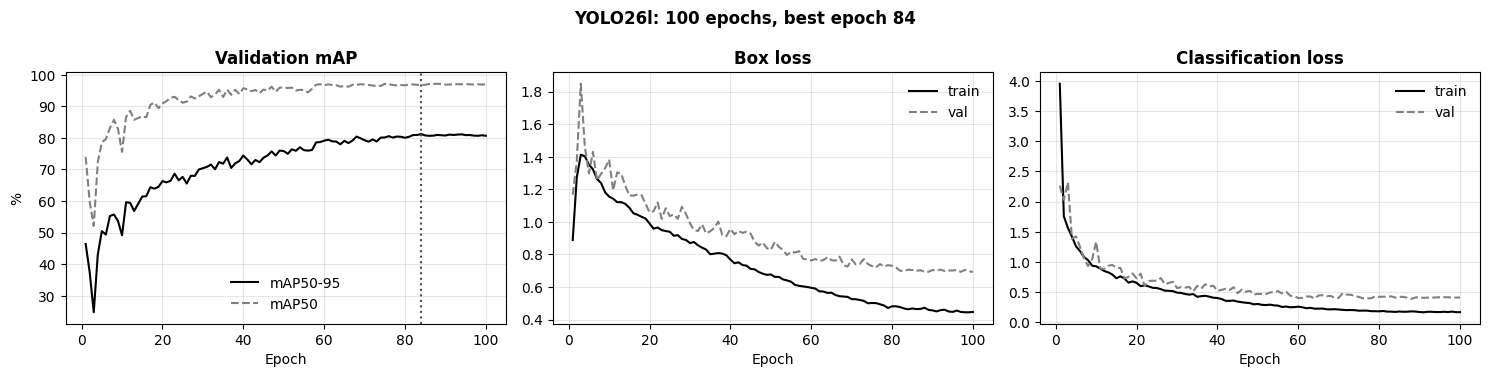

In [7]:
hist = pd.read_csv(run_dir / 'results.csv'); hist.columns = [c.strip() for c in hist.columns]
ep = hist['epoch'] if 'epoch' in hist else np.arange(1, len(hist) + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(ep, hist['metrics/mAP50-95(B)'] * 100, 'k-', label='mAP50-95')
axes[0].plot(ep, hist['metrics/mAP50(B)'] * 100, '--', color='0.5', label='mAP50')
axes[0].axvline(log['best_epoch'], color='0.3', ls=':'); axes[0].set_title('Validation mAP', fontweight='bold'); axes[0].set_ylabel('%')
axes[1].plot(ep, hist['train/box_loss'], 'k-', label='train'); axes[1].plot(ep, hist['val/box_loss'], '--', color='0.5', label='val')
axes[1].set_title('Box loss', fontweight='bold')
axes[2].plot(ep, hist['train/cls_loss'], 'k-', label='train'); axes[2].plot(ep, hist['val/cls_loss'], '--', color='0.5', label='val')
axes[2].set_title('Classification loss', fontweight='bold')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.grid(alpha=0.3); ax.legend(frameon=False)
fig.suptitle(f"YOLO26l: {log['epochs']} epochs, best epoch {log['best_epoch']}", fontweight='bold')
plt.tight_layout(); plt.savefig(RESULTS / 'training_curves.png', dpi=200); plt.show()

## Section 8: Validation and Test Results

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26l summary (fused): 188 layers, 24,751,137 parameters, 0 gradients, 86.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1940.6±540.1 MB/s, size: 96.6 KB)
val: Scanning /content/converted_datasets/isy5002-g14-dataset-e1fa4d7c/labels/val.cache... 332 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 332/332 116.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 1.8it/s 11.7s
                   all        332        457       0.97      0.931      0.967      0.811
Speed: 1.2ms preprocess, 28.8ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/drive/MyDrive/WildLens_TRAINING/results_yolo26l/val
Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26l summary (fused): 188 layers, 24,751,137 parameters, 0 gradients, 86.5 GFLOPs
val: Fast image access ✅ (pin

,Validation,Test
Precision (conf 0.001),0.970351,0.955473
Recall (conf 0.001),0.930571,0.91836
mAP50 (conf 0.001),0.967323,0.966814
mAP50-95 (conf 0.001),0.810865,0.795179
Recall (conf 0.25),0.947484,0.951477
Operational accuracy (conf 0.25),0.941865,0.925355
Pure species accuracy (conf 0.25),0.995028,0.989988
Correct / Wrong / FP / Missed,433 / 2 / 28 / 22,451 / 5 / 37 / 18
Inference ms/image (T4),28.798836,29.369951
Training time (min),193.4,NaN


,Class,Correct,Wrong,FP,Missed,Op. acc.,Pure acc.
0,buffalo,53,0,7,5,88.3%,100.0%
1,elephant,70,3,12,5,82.4%,95.9%
2,rhino,41,0,0,1,100.0%,100.0%
3,zebra,80,0,15,0,84.2%,100.0%
4,okapi,79,0,1,2,98.8%,100.0%
5,leopard,61,0,1,1,98.4%,100.0%
6,cheetah,67,2,1,4,95.7%,97.1%


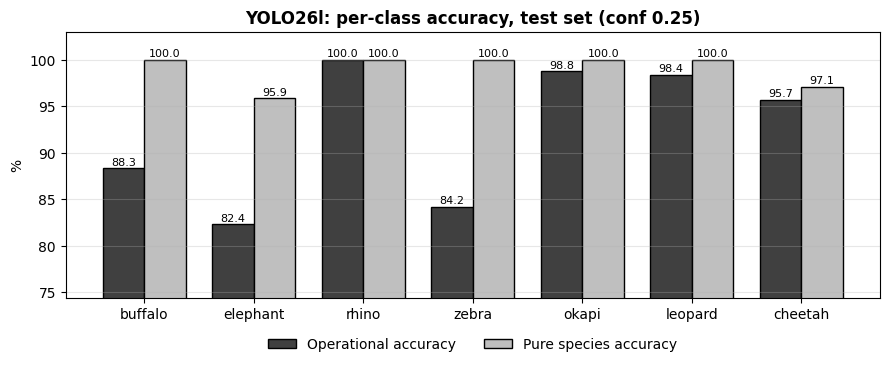

In [8]:
model = YOLO(str(best_pt))

def class_table(res):
    cm = res.confusion_matrix.matrix; names = res.names; n = len(names); rows = []
    for c in range(n):
        correct = int(cm[c, c]); wrong = int(cm[c, :n].sum() - correct); fp = int(cm[c, n]); missed = int(cm[n, c])
        rows.append({'Class': names[c], 'Correct': correct, 'Wrong': wrong, 'FP': fp, 'Missed': missed,
                     'Op. acc.': correct / max(correct + wrong + fp, 1), 'Pure acc.': correct / max(correct + wrong, 1)})
    return pd.DataFrame(rows)

def op_val(split, conf):
    # plots=True is needed to fill the confusion matrix
    return model.val(data=DATA, split=split, imgsz=IMGSZ, batch=BATCH, conf=conf, verbose=False, plots=True,
                     project=str(RESULTS / 'confusion_runs'), name=f'{split}_conf{conf:.2f}', exist_ok=True)

std, op = {}, {}
for split in ['val', 'test']:
    std[split] = model.val(data=DATA, split=split, imgsz=IMGSZ, batch=BATCH, verbose=False, plots=True,
                           project=str(RESULTS), name=split, exist_ok=True)
    op[split] = class_table(op_val(split, CONF_OP))

def summary(split):
    s, t = std[split], op[split]
    n_gt = t.Correct.sum() + t.Wrong.sum() + t.Missed.sum()
    return {'Precision (conf 0.001)': s.box.mp, 'Recall (conf 0.001)': s.box.mr,
            'mAP50 (conf 0.001)': s.box.map50, 'mAP50-95 (conf 0.001)': s.box.map,
            'Recall (conf 0.25)': t.Correct.sum() / n_gt, 'Operational accuracy (conf 0.25)': t['Op. acc.'].mean(),
            'Pure species accuracy (conf 0.25)': t['Pure acc.'].mean(),
            'Correct / Wrong / FP / Missed': f'{t.Correct.sum()} / {t.Wrong.sum()} / {t.FP.sum()} / {t.Missed.sum()}',
            'Inference ms/image (T4)': s.speed['inference']}
vt = pd.DataFrame({'Validation': summary('val'), 'Test': summary('test')})
vt.loc['Training time (min)'] = [round(log['minutes'], 1), None]
vt.to_csv(RESULTS / 'val_vs_test.csv')
display(vt)

op['test'].to_csv(RESULTS / 'per_class_test.csv', index=False)
display(op['test'].style.format({'Op. acc.': '{:.1%}', 'Pure acc.': '{:.1%}'}))

t = op['test']
fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(len(t)); w = 0.38
ax.bar(x - w / 2, t['Op. acc.'] * 100, w, color='0.25', edgecolor='black', label='Operational accuracy')
ax.bar(x + w / 2, t['Pure acc.'] * 100, w, color='0.75', edgecolor='black', label='Pure species accuracy')
for i, (a, b) in enumerate(zip(t['Op. acc.'], t['Pure acc.'])):
    ax.text(i - w / 2, a * 100 + 0.3, f'{a * 100:.1f}', ha='center', fontsize=8); ax.text(i + w / 2, b * 100 + 0.3, f'{b * 100:.1f}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(t.Class); ax.set_ylabel('%'); ax.set_ylim(max(0, t['Op. acc.'].min() * 100 - 8), 103)
ax.grid(axis='y', alpha=0.3); ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.1))
ax.set_title('YOLO26l: per-class accuracy, test set (conf 0.25)', fontweight='bold')
plt.tight_layout(); plt.savefig(RESULTS / 'per_class_test.png', dpi=200); plt.show()

## Section 9: Confidence Threshold Sweep

In [ ]:
rows = []
for split in ['val', 'test']:
    for conf in SWEEP_CONFS:
        t = class_table(op_val(split, conf))
        rows.append({'Split': split, 'Conf': conf, 'Correct': t.Correct.sum(), 'Wrong': t.Wrong.sum(), 'FP': t.FP.sum(), 'Missed': t.Missed.sum(),
                     'Recall': t.Correct.sum() / (t.Correct.sum() + t.Wrong.sum() + t.Missed.sum()), 'Op. acc.': t['Op. acc.'].mean()})
sweep = pd.DataFrame(rows)
sweep.to_csv(RESULTS / 'threshold_sweep.csv', index=False)

# final threshold: highest conf with validation recall within 2 points of conf 0.25
v = sweep[sweep.Split == 'val'].sort_values('Conf')
r0 = v.Recall.iloc[0] * 100
FINAL = float(v[v.Recall * 100 >= r0 - 2].Conf.max())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(v.Conf, v['Op. acc.'] * 100, 'k-o', label='Operational accuracy')
ax.plot(v.Conf, v.Recall * 100, '--s', color='0.5', label='Recall')
ax.axhspan(r0 - 2, r0, color='0.85', alpha=0.6, lw=0, label='Recall within 2 points of conf 0.25')
ax.axvline(FINAL, color='0.2', ls=':', lw=1.5); ax.text(FINAL + 0.01, ax.get_ylim()[0] + 2, f'final\nconf {FINAL:.2f}', fontsize=10)
ax.set_xticks(SWEEP_CONFS); ax.set_xlabel('Confidence threshold'); ax.set_ylabel('%'); ax.grid(alpha=0.3)
ax.legend(loc='lower left', fontsize=8, frameon=False); ax.set_title('YOLO26l: threshold sweep, validation set', fontweight='bold')
plt.tight_layout(); plt.savefig(RESULTS / 'threshold_sweep.png', dpi=200); plt.show()

display(sweep.pivot(index='Conf', columns='Split', values=['Recall', 'Op. acc.', 'FP', 'Missed']).round(3))
t = sweep[(sweep.Split == 'test') & (sweep.Conf == FINAL)].iloc[0]
deploy = pd.DataFrame([{'Final conf': FINAL, 'Test recall': t.Recall, 'Test op. acc.': t['Op. acc.'], 'Test FP': t.FP, 'Test missed': t.Missed}])
deploy.to_csv(RESULTS / 'final_deployment_setting.csv', index=False)
display(deploy.style.format({'Final conf': '{:.2f}', 'Test recall': '{:.1%}', 'Test op. acc.': '{:.1%}'}))

## Section 10: Save and Download

In [11]:
shutil.copy2(best_pt, RESULTS / 'yolo26l_best.pt')
shutil.copy2(run_dir / 'results.csv', RESULTS / 'training_results.csv')
for f in ['results.png', 'confusion_matrix.png', 'labels.jpg']:
    if (run_dir / f).exists():
        shutil.copy2(run_dir / f, RESULTS / f'train_{f}')
archive = shutil.make_archive('/content/yolo26l_results', 'zip', RESULTS)
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>